# Hyperparameter tuning: does tuning improve the reduced-feature risk models?
**Lilly · CAP 3764 · Fall 2026**

This notebook tunes two models from the team's modeling module, logistic regression and gradient boosting, on the **reduced feature set** only. It reports the best settings, compares cross-validated and test PR-AUC before and after tuning, and says honestly whether tuning helped.

The reduced set drops `Debt_Equity_Ratio`, `Cash_Flow` and `Total_Liabilities`. `docs/MODELING_NOTES.md` explains why: with those columns, the models mostly rediscover how the label seems to have been assigned. Notebook 06 (Jorlfran) examines that in detail; this notebook follows the team brief and does not re-test it.

Run with **Python (cap3764-risk)** from the repository root or `notebooks/`, after the raw data is downloaded and cleaned (`python src/risk_data/collect.py`, then `python src/risk_data/clean.py`, or run notebook 00). One chart is saved to `reports/figures/tuning_pr_auc.png`.

## 1. Load the data and reuse the team's split
Loading, identifier removal and the stratified 80/20 split come from `risk_data.modeling`, with `random_state=42`. This is the same split as notebooks 04 and 05, so results are comparable. **All tuning uses the training rows only.** The test rows are looked at once, at the end.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from risk_data import modeling as m

root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists()), None)
if root is None:
    raise FileNotFoundError("Run from the repository root or the notebooks folder")
figure_dir = root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")

excluded = ["Debt_Equity_Ratio", "Cash_Flow", "Total_Liabilities"]

df = m.load_model_data()
assert not df.isna().any().any(), "Review missing-value handling before modeling"
assert set(df[m.TARGET].unique()) == {0, 1}, "Expected binary risk labels"

X, y = m.split_features(df)
assert set(excluded).issubset(X.columns)
X_train, X_test, y_train, y_test = m.make_train_test_split(X, y)
assert set(X_train.index).isdisjoint(X_test.index)

features = [c for c in X_train.columns if c not in excluded]
X_train_r, X_test_r = X_train[features], X_test[features]

display(pd.DataFrame({
    "Records": [len(y_train), len(y_test)],
    "At-risk records": [int(y_train.sum()), int(y_test.sum())],
    "At-risk share": [y_train.mean(), y_test.mean()],
}, index=["Training", "Test"]))
print(f"Reduced feature set: {len(features)} predictors (dropped: {', '.join(excluded)})")

,Records,At-risk records,At-risk share
Training,2860,460,0.160839
Test,715,115,0.160839


Reduced feature set: 14 predictors (dropped: Debt_Equity_Ratio, Cash_Flow, Total_Liabilities)


## 2. Baseline: the untuned models on the reduced features
Before tuning we need a starting point. The team's default settings are scored with the same 5-fold stratified cross-validation (`StratifiedKFold`, shuffled, `random_state=42`) that `risk_data.modeling.cross_validate_models` uses, and then evaluated once on the test rows.

**PR-AUC** here means average precision (`average_precision`), as in the shared module. It summarizes the precision-recall curve and focuses on the rare at-risk class. A model that guesses at random scores about the share of at-risk companies, shown below as the no-skill level.

In [2]:
cv = StratifiedKFold(n_splits=m.CV_SPLITS, shuffle=True, random_state=m.RANDOM_STATE)

model_keys = {"Logistic regression": "logistic_regression", "Gradient boosting": "gradient_boosting"}
baseline_models = {label: m.build_models(X_train_r)[key] for label, key in model_keys.items()}

baseline_cv = m.cross_validate_models(baseline_models, X_train_r, y_train)
baseline_test = {}
for label, model in baseline_models.items():
    model.fit(X_train_r, y_train)
    baseline_test[label] = m.evaluate(model, X_test_r, y_test)

no_skill_test = average_precision_score(y_test, np.full(len(y_test), y_train.mean()))
print(f"No-skill PR-AUC: {no_skill_test:.3f} (share of at-risk companies)")

display(baseline_cv[["pr_auc_mean", "pr_auc_std"]].rename(
    columns={"pr_auc_mean": "CV PR-AUC (mean)", "pr_auc_std": "CV PR-AUC (std)"}))

No-skill PR-AUC: 0.161 (share of at-risk companies)


,CV PR-AUC (mean),CV PR-AUC (std)
Logistic regression,0.322892,0.055230
Gradient boosting,0.409744,0.058416


## 3. Grid search on the training rows
`GridSearchCV` tries every combination in a grid and keeps the one with the best cross-validated PR-AUC (`scoring="average_precision"`, using the same `StratifiedKFold` object as above). The model is a full pipeline, so scaling and encoding are re-learned inside each fold with no leakage.

| Model | Settings searched |
|-------|-------------------|
| Logistic regression | `C` (inverse regularization strength; smaller = stronger regularization) |
| Gradient boosting | `learning_rate`, `max_depth` (`None` = no limit), `max_iter` (number of boosting rounds) |

Each grid includes the model's default setting, so tuning can never score worse than the baseline on the cross-validation folds. Only the training rows are used here.

In [3]:
param_grids = {
    "Logistic regression": {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "Gradient boosting": {
        "model__learning_rate": [0.03, 0.1, 0.3],
        "model__max_depth": [2, 3, 5, None],
        "model__max_iter": [50, 100, 200],
    },
}

searches = {}
for label, key in model_keys.items():
    search = GridSearchCV(
        m.build_models(X_train_r)[key],
        param_grids[label],
        scoring="average_precision",
        cv=cv,
        n_jobs=1,
        refit=True,
    )
    search.fit(X_train_r, y_train)
    searches[label] = search
    print(f"{label}: {len(search.cv_results_['params'])} combinations tried")

Logistic regression: 6 combinations tried
Gradient boosting: 36 combinations tried


In [4]:
for label, search in searches.items():
    best = search.best_index_
    display(Markdown(f"### {label}"))
    print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
    print(f"Best CV PR-AUC: {search.best_score_:.4f} (std across folds {search.cv_results_['std_test_score'][best]:.4f})")
    top = (pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
           .sort_values("rank_test_score").head(5).reset_index(drop=True))
    top["params"] = top["params"].apply(lambda p: {k.replace("model__", ""): v for k, v in p.items()})
    display(top)

    # Sanity check: the default setting is in the grid, so tuning cannot do worse than the baseline.
    assert search.best_score_ >= baseline_cv.loc[label, "pr_auc_mean"] - 1e-4, "Tuned CV score is below the baseline"

### Logistic regression

Best settings: {'C': 100}
Best CV PR-AUC: 0.3234 (std across folds 0.0557)


,params,mean_test_score,std_test_score,rank_test_score
0,{'C': 100},0.323440,0.055698,1
1,{'C': 10},0.323440,0.055706,2
2,{'C': 1},0.322892,0.055230,3
3,{'C': 0.1},0.320808,0.054129,4
4,{'C': 0.01},0.314346,0.055018,5


### Gradient boosting

Best settings: {'learning_rate': 0.1, 'max_depth': None, 'max_iter': 100}
Best CV PR-AUC: 0.4097 (std across folds 0.0584)


,params,mean_test_score,std_test_score,rank_test_score
0,"{'learning_rate': 0.1, 'max_depth': None, 'max...",0.409744,0.058416,1
1,"{'learning_rate': 0.1, 'max_depth': None, 'max...",0.407130,0.054690,2
2,"{'learning_rate': 0.1, 'max_depth': None, 'max...",0.405104,0.053131,3
3,"{'learning_rate': 0.03, 'max_depth': None, 'ma...",0.399383,0.053055,4
4,"{'learning_rate': 0.3, 'max_depth': 2, 'max_it...",0.396490,0.039533,5


## 4. Compare tuned and untuned models
For each model we compare cross-validated PR-AUC (on the training rows) with PR-AUC on the held-out test rows.

- The **tuned CV score is slightly optimistic**: it is the best of many tries on the same folds. The test score is the fairer number because the test rows played no part in choosing the settings.
- Precision, recall and F1 use the default 0.5 probability threshold. We tuned for PR-AUC, not for those.

In [5]:
rows = []
for label in model_keys:
    search = searches[label]
    tuned_test = m.evaluate(search.best_estimator_, X_test_r, y_test)
    rows.append({
        "Model": label, "Version": "Untuned",
        "CV PR-AUC": baseline_cv.loc[label, "pr_auc_mean"], "CV std": baseline_cv.loc[label, "pr_auc_std"],
        "Test PR-AUC": baseline_test[label]["pr_auc"], "Test ROC-AUC": baseline_test[label]["roc_auc"],
        "Test precision": baseline_test[label]["precision"], "Test recall": baseline_test[label]["recall"],
        "Test F1": baseline_test[label]["f1"],
    })
    rows.append({
        "Model": label, "Version": "Tuned",
        "CV PR-AUC": search.best_score_, "CV std": search.cv_results_["std_test_score"][search.best_index_],
        "Test PR-AUC": tuned_test["pr_auc"], "Test ROC-AUC": tuned_test["roc_auc"],
        "Test precision": tuned_test["precision"], "Test recall": tuned_test["recall"],
        "Test F1": tuned_test["f1"],
    })

comparison = pd.DataFrame(rows).set_index(["Model", "Version"])
display(comparison.round(4))
print(f"No-skill PR-AUC on the test rows: {no_skill_test:.3f}")

CV PR-AUC  CV std  Test PR-AUC  Test ROC-AUC  \
Model               Version                                                 
Logistic regression Untuned     0.3229  0.0552       0.3415        0.6331   
                    Tuned       0.3234  0.0557       0.3416        0.6330   
Gradient boosting   Untuned     0.4097  0.0584       0.3784        0.6067   
                    Tuned       0.4097  0.0584       0.3784        0.6067   

                             Test precision  Test recall  Test F1  
Model               Version                                        
Logistic regression Untuned          0.2214       0.5217   0.3109  
                    Tuned            0.2214       0.5217   0.3109  
Gradient boosting   Untuned          0.3939       0.2261   0.2873  
                    Tuned            0.3939       0.2261   0.2873

No-skill PR-AUC on the test rows: 0.161


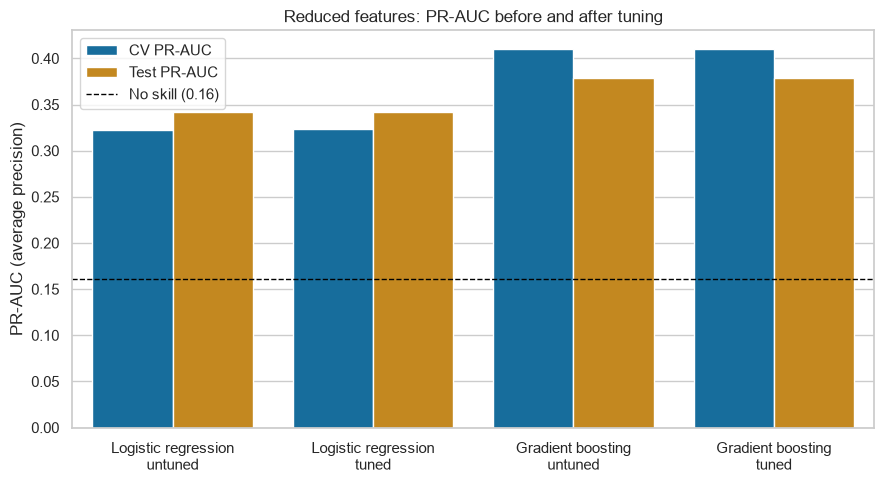

In [6]:
plot_df = comparison.reset_index().melt(
    id_vars=["Model", "Version"], value_vars=["CV PR-AUC", "Test PR-AUC"],
    var_name="Score", value_name="PR-AUC")
plot_df["Model and version"] = plot_df["Model"] + "\n" + plot_df["Version"].str.lower()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_df, x="Model and version", y="PR-AUC", hue="Score", ax=ax)
ax.axhline(no_skill_test, color="black", linestyle="--", linewidth=1, label=f"No skill ({no_skill_test:.2f})")
ax.set(title="Reduced features: PR-AUC before and after tuning",
       ylabel="PR-AUC (average precision)", xlabel="")
ax.legend(title="")
fig.tight_layout()
fig.savefig(figure_dir / "tuning_pr_auc.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Did tuning help?
 To avoid over-reading small differences, we compare each change with the **cross-validation standard deviation** of the untuned model: a change smaller than one standard deviation is called "within noise", because splitting the data differently could easily have produced it.

The two models differ slightly between cross-validation and the test set. Gradient boosting scored a bit lower on the test set (0.378) than in cross-validation (0.410), while logistic regression scored a bit higher (0.342 vs 0.323). This is expected given the small number of at-risk companies in the test set. Tuning did not change either model’s scores, because the best settings found were the same as, or nearly the same as, the defaults. This suggests the limit is the information in the data, not the model settings.

In [7]:
sentences = [
    f"On the reduced features, a model with no skill would score a PR-AUC of about {no_skill_test:.3f}."
]
for label in model_keys:
    untuned = comparison.loc[(label, "Untuned")]
    tuned = comparison.loc[(label, "Tuned")]
    noise = untuned["CV std"]
    cv_change = tuned["CV PR-AUC"] - untuned["CV PR-AUC"]
    test_change = tuned["Test PR-AUC"] - untuned["Test PR-AUC"]
    if abs(test_change) < noise:
        verdict = "a change within noise, so tuning did not clearly help or hurt"
    elif test_change > 0:
        verdict = "an improvement larger than the cross-validation noise"
    else:
        verdict = "a drop larger than the cross-validation noise"
    best = {k.replace("model__", ""): v for k, v in searches[label].best_params_.items()}
    sentences.append(
        f"{label}: best settings {best}. Cross-validated PR-AUC went from {untuned['CV PR-AUC']:.3f} to "
        f"{tuned['CV PR-AUC']:.3f} ({cv_change:+.3f}), and test PR-AUC from {untuned['Test PR-AUC']:.3f} to "
        f"{tuned['Test PR-AUC']:.3f} ({test_change:+.3f}), {verdict} (untuned CV standard deviation {noise:.3f})."
    )

best_label = comparison.xs("Tuned", level="Version")["Test PR-AUC"].idxmax()
best_test = comparison.loc[(best_label, "Tuned"), "Test PR-AUC"]
sentences.append(
    f"The highest tuned test PR-AUC is {best_test:.3f} ({best_label.lower()}), compared with {no_skill_test:.3f} for no skill."
)
display(Markdown("\n\n".join(f"- {s}" for s in sentences)))

- On the reduced features, a model with no skill would score a PR-AUC of about 0.161.

- Logistic regression: best settings {'C': 100}. Cross-validated PR-AUC went from 0.323 to 0.323 (+0.001), and test PR-AUC from 0.342 to 0.342 (+0.000), a change within noise, so tuning did not clearly help or hurt (untuned CV standard deviation 0.055).

- Gradient boosting: best settings {'learning_rate': 0.1, 'max_depth': None, 'max_iter': 100}. Cross-validated PR-AUC went from 0.410 to 0.410 (+0.000), and test PR-AUC from 0.378 to 0.378 (+0.000), a change within noise, so tuning did not clearly help or hurt (untuned CV standard deviation 0.058).

- The highest tuned test PR-AUC is 0.378 (gradient boosting), compared with 0.161 for no skill.

## 6. Limits
- **Weak signal:** without the three suspect columns, scores sit well below the near-perfect all-features results, so tuning has little room to help. Gains from a model that is only modestly better than no skill should not be oversold.
- **Optimistic tuned CV score:** the tuned cross-validation score is the best of many tries on the same folds. The test score is the honest comparison. A nested cross-validation would remove this bias but was not run here.
- **Small test set:** the test rows contain only a few hundred at-risk companies at most, so one test score can move by chance. That is why changes are compared with the cross-validation spread.
- **Test-set reuse:** notebooks 04 and 05 already looked at these test rows. Here they were used only to report final scores, never to choose settings. Do not change the features or grids in response to these test scores and then claim a new independent test result.
- **Proxy variables:** related inputs such as `Net_Income` may still carry the information of the removed columns, so removing three features does not prove leakage is gone (see notebook 06).
- **Meaning of the label:** the target is the dataset's binary label, with no stated time horizon. These results do not show what causes financial distress or predict real-world default.

## 7. Reproducibility
Same split and seed (`random_state=42`) as notebooks 04 and 05; the same shuffled 5-fold `StratifiedKFold` as `risk_data.modeling`; preprocessing inside the pipelines. Restart the kernel and run all cells. No new packages are needed beyond the pinned environment, and no data are committed.